# 1-amaliy mashg‘ulot (A1)
## Simsiz tarmoqlarni modellashtirish uchun dasturiy muhit bilan tanishish

**Muhit:** Python + Google Colab  
**Maqsad:** parametr → model → hisoblash → KPI → grafik → tahlil ketma-ketligini o‘zlashtirish.

> Eslatma: A1 — o‘quv maqsadidagi soddalashtirilgan model. Path loss, fading, shadowing, SINR, MCS, interferensiya va 3GPP PRB mexanizmlari keyingi amaliy ishlarda ko‘rib chiqiladi.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Matplotlib:', plt.matplotlib.__version__)

NumPy: 2.3.5
Pandas: 2.2.3
Matplotlib: 3.10.8


## 1. Variantni tanlash
`VARIANT` qiymatini 1–15 oralig‘ida belgilang. Spektral samaradorlik A1 doirasida barcha variantlar uchun **2.0 bit/s/Hz** qilib o‘zgarmas qoldiriladi.

In [2]:
VARIANT = 1  # <-- shu qiymatni o'zingizning variantingizga almashtiring

variants = {
    1:  dict(area_width_m=1000, area_height_m=1000, n_ue=20, coverage_radius_m=450, bandwidth_mhz=20, demand_min_mbps=1, demand_max_mbps=8, seed=101),
    2:  dict(area_width_m=800,  area_height_m=800,  n_ue=18, coverage_radius_m=350, bandwidth_mhz=10, demand_min_mbps=1, demand_max_mbps=7, seed=102),
    3:  dict(area_width_m=1200, area_height_m=800,  n_ue=25, coverage_radius_m=420, bandwidth_mhz=20, demand_min_mbps=2, demand_max_mbps=9, seed=103),
    4:  dict(area_width_m=1000, area_height_m=1000, n_ue=30, coverage_radius_m=400, bandwidth_mhz=20, demand_min_mbps=1, demand_max_mbps=10, seed=104),
    5:  dict(area_width_m=1200, area_height_m=1200, n_ue=35, coverage_radius_m=500, bandwidth_mhz=40, demand_min_mbps=2, demand_max_mbps=12, seed=105),
    6:  dict(area_width_m=900,  area_height_m=700,  n_ue=22, coverage_radius_m=320, bandwidth_mhz=10, demand_min_mbps=1, demand_max_mbps=6, seed=106),
    7:  dict(area_width_m=1500, area_height_m=1000, n_ue=28, coverage_radius_m=550, bandwidth_mhz=20, demand_min_mbps=2, demand_max_mbps=10, seed=107),
    8:  dict(area_width_m=1000, area_height_m=800,  n_ue=24, coverage_radius_m=380, bandwidth_mhz=15, demand_min_mbps=1, demand_max_mbps=8, seed=108),
    9:  dict(area_width_m=1200, area_height_m=900,  n_ue=32, coverage_radius_m=450, bandwidth_mhz=30, demand_min_mbps=2, demand_max_mbps=11, seed=109),
    10: dict(area_width_m=800,  area_height_m=1200, n_ue=20, coverage_radius_m=400, bandwidth_mhz=20, demand_min_mbps=1, demand_max_mbps=9, seed=110),
    11: dict(area_width_m=1400, area_height_m=1400, n_ue=40, coverage_radius_m=600, bandwidth_mhz=40, demand_min_mbps=2, demand_max_mbps=14, seed=111),
    12: dict(area_width_m=1000, area_height_m=600,  n_ue=18, coverage_radius_m=300, bandwidth_mhz=10, demand_min_mbps=1, demand_max_mbps=5, seed=112),
    13: dict(area_width_m=1100, area_height_m=1100, n_ue=27, coverage_radius_m=480, bandwidth_mhz=25, demand_min_mbps=2, demand_max_mbps=10, seed=113),
    14: dict(area_width_m=1300, area_height_m=900,  n_ue=33, coverage_radius_m=500, bandwidth_mhz=30, demand_min_mbps=3, demand_max_mbps=12, seed=114),
    15: dict(area_width_m=900,  area_height_m=900,  n_ue=26, coverage_radius_m=420, bandwidth_mhz=20, demand_min_mbps=1, demand_max_mbps=9, seed=115),
}

if VARIANT not in variants:
    raise ValueError('VARIANT 1 dan 15 gacha bo‘lishi kerak.')

params = variants[VARIANT].copy()
params['spectral_efficiency'] = 2.0
params

{'area_width_m': 1000,
 'area_height_m': 1000,
 'n_ue': 20,
 'coverage_radius_m': 450,
 'bandwidth_mhz': 20,
 'demand_min_mbps': 1,
 'demand_max_mbps': 8,
 'seed': 101,
 'spectral_efficiency': 2.0}

## 2. Simulyatsiya funksiyasi

Modelda BS xizmat hududining markaziga qo‘yiladi. UE koordinatalari bir tekis tasodifiy taqsimotdan hosil qilinadi. Qamrov ichidagi UE lar umumiy polosani teng ulashadi.  

- `max_service_rate_mbps = allocated_bandwidth × spectral_efficiency` — **soddalashtirilgan maksimal xizmat tezligi**;
- `throughput = min(demand, max_service_rate)`;
- `satisfaction = throughput / demand`.


In [3]:
def simulate(params):
    rng = np.random.default_rng(params['seed'])

    x_bs = params['area_width_m'] / 2
    y_bs = params['area_height_m'] / 2

    x = rng.uniform(0, params['area_width_m'], params['n_ue'])
    y = rng.uniform(0, params['area_height_m'], params['n_ue'])
    distance = np.hypot(x - x_bs, y - y_bs)
    in_coverage = distance <= params['coverage_radius_m']

    demand = rng.uniform(
        params['demand_min_mbps'],
        params['demand_max_mbps'],
        params['n_ue']
    )

    n_covered = int(in_coverage.sum())
    bw_share = params['bandwidth_mhz'] / n_covered if n_covered else 0.0

    max_service_rate = np.where(
        in_coverage,
        bw_share * params['spectral_efficiency'],
        0.0
    )

    throughput = np.minimum(demand, max_service_rate)
    satisfaction = np.divide(
        throughput, demand,
        out=np.zeros_like(throughput),
        where=demand > 0
    )

    df = pd.DataFrame({
        'UE': [f'UE-{i+1:02d}' for i in range(params['n_ue'])],
        'x_m': x,
        'y_m': y,
        'distance_m': distance,
        'in_coverage': in_coverage,
        'demand_mbps': demand,
        'allocated_bw_mhz': np.where(in_coverage, bw_share, 0.0),
        'max_service_rate_mbps': max_service_rate,
        'throughput_mbps': throughput,
        'satisfaction': satisfaction
    })

    metrics = {
        'n_covered': n_covered,
        'coverage_percent': 100 * n_covered / params['n_ue'],
        'bw_share_mhz': bw_share,
        'total_demand_mbps': demand.sum(),
        'total_throughput_mbps': throughput.sum(),
        'avg_throughput_all_mbps': throughput.mean(),
        'avg_satisfaction_all_percent': 100 * satisfaction.mean(),
        'avg_satisfaction_covered_percent': (
            100 * satisfaction[in_coverage].mean() if n_covered else 0.0
        )
    }
    return x_bs, y_bs, df, metrics

In [4]:
x_bs, y_bs, df, metrics = simulate(params)
display(df.round(3))

print(f"Qamrovdagi UE: {metrics['n_covered']}/{params['n_ue']}")
print(f"Qamrov ulushi: {metrics['coverage_percent']:.2f}%")
print(f"Har bir qamrovdagi UE uchun polosa: {metrics['bw_share_mhz']:.3f} MHz")
print(f"Umumiy trafik talabi: {metrics['total_demand_mbps']:.3f} Mbit/s")
print(f"Umumiy throughput: {metrics['total_throughput_mbps']:.3f} Mbit/s")
print(f"O‘rtacha throughput (barcha UE): {metrics['avg_throughput_all_mbps']:.3f} Mbit/s")
print(f"Satisfaction (barcha UE): {metrics['avg_satisfaction_all_percent']:.2f}%")
print(f"Satisfaction (qamrovdagi UE): {metrics['avg_satisfaction_covered_percent']:.2f}%")

,UE,x_m,y_m,distance_m,in_coverage,demand_mbps,allocated_bw_mhz,max_service_rate_mbps,throughput_mbps,satisfaction
0,UE-01,943.533,507.580,443.597,True,4.234,1.333,2.667,2.667,0.630
1,UE-02,359.421,370.936,190.840,True,1.646,1.333,2.667,1.646,1.000
2,UE-03,784.805,55.203,528.165,False,4.444,0.000,0.000,0.000,0.000
3,UE-04,591.278,250.409,265.758,True,2.603,1.333,2.667,2.603,1.000
4,UE-05,294.329,840.963,398.192,True,1.652,1.333,2.667,1.652,1.000
5,UE-06,922.726,818.154,529.074,False,1.639,0.000,0.000,0.000,0.000
6,UE-07,869.332,667.325,405.467,True,2.511,1.333,2.667,2.511,1.000
7,UE-08,364.138,470.588,139.009,True,5.894,1.333,2.667,2.667,0.452
8,UE-09,973.177,969.844,666.821,False,2.254,0.000,0.000,0.000,0.000
9,UE-10,224.524,840.261,437.795,True,4.979,1.333,2.667,2.667,0.536


Qamrovdagi UE: 15/20
Qamrov ulushi: 75.00%
Har bir qamrovdagi UE uchun polosa: 1.333 MHz
Umumiy trafik talabi: 80.862 Mbit/s
Umumiy throughput: 34.412 Mbit/s
O‘rtacha throughput (barcha UE): 1.721 Mbit/s
Satisfaction (barcha UE): 53.29%
Satisfaction (qamrovdagi UE): 71.05%


## 3. Vizualizatsiya
Grafiklarning ichiga sarlavha yozilmaydi. Hisobotda rasm nomi grafikdan **keyin** alohida caption sifatida beriladi.

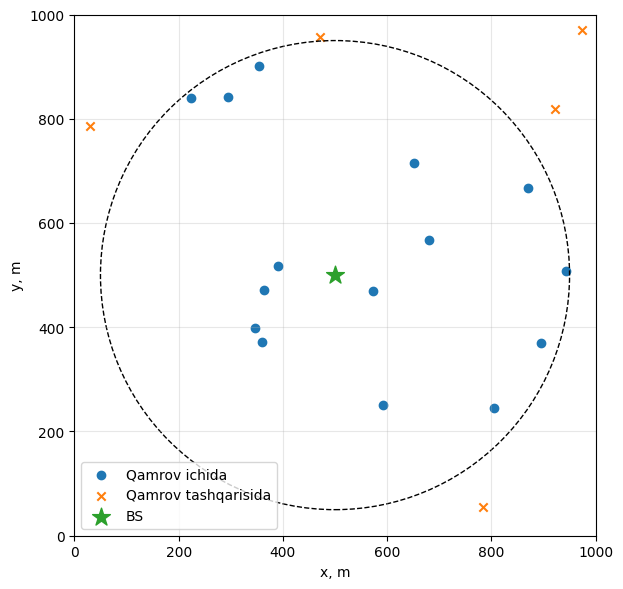

In [5]:
# 1-rasm uchun grafik: BS va UE topologiyasi
plt.figure(figsize=(7, 6))
covered = df['in_coverage']
plt.scatter(df.loc[covered, 'x_m'], df.loc[covered, 'y_m'], marker='o', label='Qamrov ichida')
plt.scatter(df.loc[~covered, 'x_m'], df.loc[~covered, 'y_m'], marker='x', label='Qamrov tashqarisida')
plt.scatter([x_bs], [y_bs], marker='*', s=180, label='BS')
plt.gca().add_patch(plt.Circle((x_bs, y_bs), params['coverage_radius_m'], fill=False, linestyle='--'))
plt.xlim(0, params['area_width_m'])
plt.ylim(0, params['area_height_m'])
plt.gca().set_aspect('equal', adjustable='box')
plt.xlabel('x, m')
plt.ylabel('y, m')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

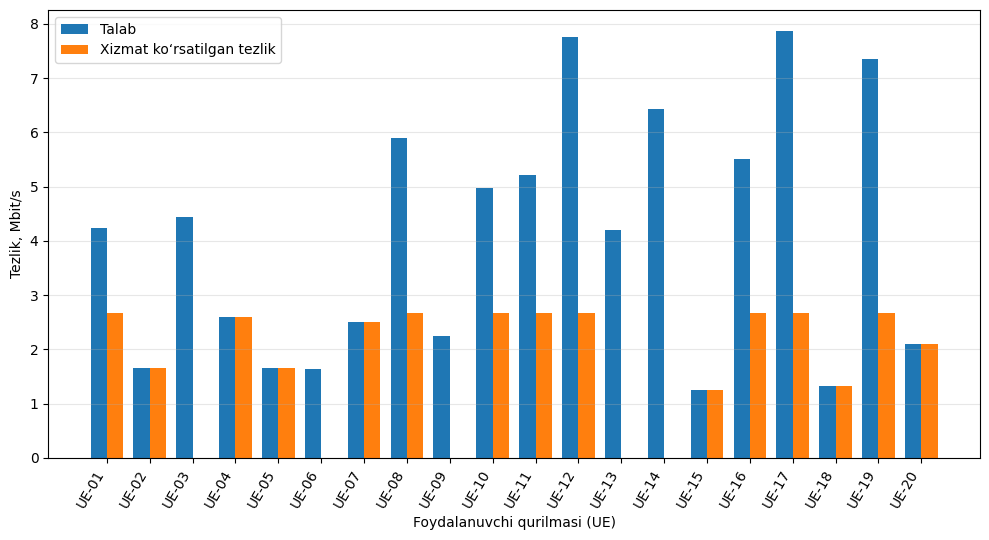

In [6]:
# 2-rasm uchun grafik: talab va throughput
idx = np.arange(len(df))
width = 0.38
plt.figure(figsize=(10, 5.5))
plt.bar(idx - width/2, df['demand_mbps'], width, label='Talab')
plt.bar(idx + width/2, df['throughput_mbps'], width, label='Xizmat ko‘rsatilgan tezlik')
plt.xlabel('Foydalanuvchi qurilmasi (UE)')
plt.ylabel('Tezlik, Mbit/s')
plt.xticks(idx, df['UE'], rotation=60, ha='right')
plt.grid(True, axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

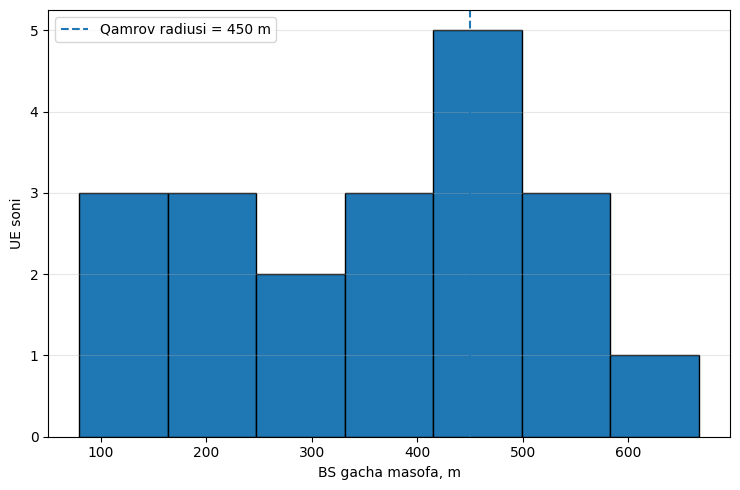

In [7]:
# 3-rasm uchun grafik: BS gacha masofalar taqsimoti
plt.figure(figsize=(7.5, 5))
plt.hist(df['distance_m'], bins=7, edgecolor='black')
plt.axvline(params['coverage_radius_m'], linestyle='--', label=f"Qamrov radiusi = {params['coverage_radius_m']} m")
plt.xlabel('BS gacha masofa, m')
plt.ylabel('UE soni')
plt.grid(True, axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Natijalarni CSV faylga saqlash

In [8]:
output_name = f'A1_v2_variant_{VARIANT:02d}_results.csv'
df.to_csv(output_name, index=False)
print('Saqlandi:', output_name)

Saqlandi: A1_v2_variant_01_results.csv


## 5. Majburiy sensitivity-tajriba
Faqat **bitta omilni** o‘zgartirib, sabab–oqibatni tahlil qiling: umumiy polosani 2 baravar oshiring, qolgan parametrlarni o‘zgartirmang.

In [9]:
params_2x = params.copy()
params_2x['bandwidth_mhz'] = 2 * params['bandwidth_mhz']
_, _, df_2x, metrics_2x = simulate(params_2x)

comparison = pd.DataFrame({
    'KPI': ['Qamrov, %', 'Umumiy throughput, Mbit/s', 'Satisfaction (barcha UE), %', 'Satisfaction (qamrovdagi UE), %'],
    'Asosiy': [metrics['coverage_percent'], metrics['total_throughput_mbps'], metrics['avg_satisfaction_all_percent'], metrics['avg_satisfaction_covered_percent']],
    'Bandwidth x2': [metrics_2x['coverage_percent'], metrics_2x['total_throughput_mbps'], metrics_2x['avg_satisfaction_all_percent'], metrics_2x['avg_satisfaction_covered_percent']]
})
display(comparison.round(3))

,KPI,Asosiy,Bandwidth x2
0,"Qamrov, %",75.000,75.000
1,"Umumiy throughput, Mbit/s",34.412,54.176
2,"Satisfaction (barcha UE), %",53.290,69.815
3,"Satisfaction (qamrovdagi UE), %",71.053,93.087


## 6. Qo‘shimcha ilmiy tahlil (tavsiya etiladi)
Bitta `seed` reproduktiv **bitta realizatsiya** beradi. Stoxastik modelni umumlashtirish uchun 30 ta turli `seed` bilan qisqa Monte-Carlo tajribasi bajarish mumkin. Bu qism Colab CPU muhitida juda yengil ishlaydi.

In [10]:
multi_run = []
for seed in range(1, 31):
    p = params.copy()
    p['seed'] = seed
    _, _, _, m = simulate(p)
    multi_run.append({
        'seed': seed,
        'coverage_percent': m['coverage_percent'],
        'total_throughput_mbps': m['total_throughput_mbps']
    })

mc = pd.DataFrame(multi_run)
summary = pd.DataFrame({
    'KPI': ['Qamrov, %', 'Umumiy throughput, Mbit/s'],
    'Mean': [mc['coverage_percent'].mean(), mc['total_throughput_mbps'].mean()],
    'Std': [mc['coverage_percent'].std(ddof=1), mc['total_throughput_mbps'].std(ddof=1)]
})
display(summary.round(3))

,KPI,Mean,Std
0,"Qamrov, %",63.167,10.866
1,"Umumiy throughput, Mbit/s",36.033,2.179


## 7. Talaba xulosasi
5–7 gapda quyidagilarni izohlang:
1. Qamrov ulushi nimaga bog‘liq bo‘ldi?
2. Qamrovdagi UE soni resurs ulushiga qanday ta’sir qildi?
3. Nima sababdan ayrim UE lar uchun throughput talabdan kichik bo‘ldi?
4. Bandwidth 2 baravar oshganda qaysi KPIlar o‘zgardi va nima uchun?
5. Ushbu A1 modelining asosiy cheklovlari nimalardan iborat?
